## *Experiment 03: Huấn luyện mô hình Hierarchical Two-Stage Autoencoder-MLP cho FiveDataset*

### Ý tưởng chính
Bài toán khó nhất ở cụm:
- `AML`
- `CML`
- `MDS`

Vì vậy, thay vì phân loại 6 lớp một bước, notebook này dùng **2 stage**:

#### - Stage 1
Phân loại 4 nhóm:
- `ALL`
- `CLL`
- `Healthy`
- `Myeloid`

Trong đó:
- `Myeloid = AML + CML + MDS`

#### - Stage 2
Chỉ xử lý phần khó `Myeloid`, nhưng **không dùng MLP trực tiếp trên feature gốc**.

Thay vào đó:
1. Dùng **Autoencoder** để học latent representation cho cụm Myeloid
2. Dùng **Residual MLP classifier** trên latent space để phân biệt:
   - `AML`
   - `CML`
   - `MDS`

### Bước 1. Import thư viện và khởi tạo thư mục output

In [1]:

import os
import re
import random
import zipfile
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

warnings.filterwarnings("ignore")

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def get_next_run_dir(model_root: Path) -> Path:
    model_root.mkdir(parents=True, exist_ok=True)
    pattern = re.compile(r"run(\d+)$")
    nums = []
    for p in model_root.iterdir():
        if p.is_dir():
            m = pattern.match(p.name)
            if m:
                nums.append(int(m.group(1)))
    next_num = 1 if not nums else max(nums) + 1
    return model_root / f"run{next_num:02d}"

def load_five_dataset(data_dir: Path, class_col: str = "Class") -> pd.DataFrame:
    csv_path = data_dir / "FiveDataset.csv"
    zip_path = data_dir / "FiveDataset.zip"

    if csv_path.exists():
        df = pd.read_csv(csv_path)
    elif zip_path.exists():
        with zipfile.ZipFile(zip_path, "r") as zf:
            target = None
            for name in zf.namelist():
                if name.lower().endswith(".csv") and "fivedataset" in name.lower():
                    target = name
                    break
            if target is None:
                candidates = [n for n in zf.namelist() if n.lower().endswith(".csv")]
                if not candidates:
                    raise FileNotFoundError("Không tìm thấy file CSV trong FiveDataset.zip")
                target = candidates[0]
            with zf.open(target) as f:
                df = pd.read_csv(f)
    else:
        raise FileNotFoundError("Không tìm thấy FiveDataset.csv hoặc FiveDataset.zip trong data/raw")

    if class_col not in df.columns:
        raise ValueError(f"Không tìm thấy cột nhãn '{class_col}'")
    return df

seed_everything(42)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
EXPERIMENT_ROOT = PROJECT_ROOT / "outputs" / "ex03"
RUN_DIR = get_next_run_dir(EXPERIMENT_ROOT)

FIG_DIR = RUN_DIR / "figures"
METRIC_DIR = RUN_DIR / "metrics"
MODEL_DIR = RUN_DIR / "models"

for d in [FIG_DIR, METRIC_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR:", DATA_DIR)
print("RUN_DIR:", RUN_DIR)
print("DEVICE:", DEVICE)


PROJECT_ROOT: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl
DATA_DIR: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl\data\raw
RUN_DIR: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl\outputs\ex03\run02
DEVICE: cpu


### Bước 2. Khai báo cấu hình

Cell này đặt các siêu tham số cho:
- Stage 1
- Autoencoder của Stage 2
- Classifier của Stage 2


In [2]:

CLASS_COL = "Class"
TEST_SIZE = 0.15
VAL_SIZE = 0.15
RANDOM_STATE = 42

# Stage 1
TOP_K_STAGE1 = 1000
STAGE1_BATCH_SIZE = 32
STAGE1_EPOCHS = 45
STAGE1_LR = 5e-4
STAGE1_WEIGHT_DECAY = 3e-4
STAGE1_DROPOUT = 0.30
STAGE1_PATIENCE = 8
STAGE1_HIDDEN_DIMS = (256, 128)

# Stage 2 preprocessing
TOP_K_STAGE2 = 800
LATENT_DIM_STAGE2 = 96

# Stage 2 Autoencoder
AE_STAGE2_BATCH_SIZE = 64
AE_STAGE2_EPOCHS = 50
AE_STAGE2_LR = 1e-3
AE_STAGE2_WEIGHT_DECAY = 1e-4
AE_STAGE2_DROPOUT = 0.15
AE_STAGE2_PATIENCE = 8
AE_NOISE_STD = 0.05

# Stage 2 classifier
STAGE2_BATCH_SIZE = 32
STAGE2_EPOCHS = 50
STAGE2_LR = 4e-4
STAGE2_WEIGHT_DECAY = 4e-4
STAGE2_DROPOUT = 0.35
STAGE2_PATIENCE = 8
STAGE2_HIDDEN_DIMS = (128, 64)

STAGE2_CLASS_BOOST = {
    "AML": 1.10,
    "CML": 1.20,
    "MDS": 1.15
}

print("TOP_K_STAGE1 =", TOP_K_STAGE1)
print("TOP_K_STAGE2 =", TOP_K_STAGE2)
print("LATENT_DIM_STAGE2 =", LATENT_DIM_STAGE2)


TOP_K_STAGE1 = 1000
TOP_K_STAGE2 = 800
LATENT_DIM_STAGE2 = 96


### Bước 3. Định nghĩa Dataset, model và hàm train/evaluate

In [3]:

class GeneDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class UnlabeledDataset(Dataset):
    def __init__(self, X):
        self.X = torch.tensor(X, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx]

class ResidualMLPClassifier(nn.Module):
    def __init__(self, input_dim: int, hidden_dims=(256, 128), num_classes: int = 2, dropout: float = 0.3):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, hidden_dims[0])

        layers = []
        prev = hidden_dims[0]
        for h in hidden_dims:
            layers.append(nn.Sequential(
                nn.Linear(prev, h),
                nn.BatchNorm1d(h),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(h, h),
                nn.BatchNorm1d(h)
            ))
            prev = h

        self.blocks = nn.ModuleList(layers)
        self.activ = nn.GELU()
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_dims[-1], num_classes)

    def forward(self, x):
        x = self.input_proj(x)
        for block in self.blocks:
            residual = x
            out = block(x)
            if out.shape == residual.shape:
                x = self.activ(out + residual)
            else:
                x = self.activ(out)
            x = self.drop(x)
        return self.head(x)

class DenoisingAutoencoder(nn.Module):
    def __init__(self, input_dim: int, latent_dim: int = 96, dropout: float = 0.15):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(128, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(512, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return z, x_hat

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction="mean"):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, logits, targets):
        ce_loss = nn.functional.cross_entropy(logits, targets, weight=self.alpha, reduction="none")
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss

        if self.reduction == "mean":
            return focal_loss.mean()
        elif self.reduction == "sum":
            return focal_loss.sum()
        return focal_loss

def run_cls_epoch(model, loader, criterion, device, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    all_preds, all_targets = [], []

    with torch.set_grad_enabled(is_train):
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            total_loss += loss.item() * xb.size(0)
            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(yb.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    return avg_loss, acc, macro_f1

def train_ae_epoch(model, loader, criterion, optimizer, device, noise_std=0.05):
    model.train()
    total_loss = 0.0

    for xb in loader:
        xb = xb.to(device)
        noisy_x = xb + noise_std * torch.randn_like(xb)

        _, xhat = model(noisy_x)
        loss = criterion(xhat, xb)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item() * xb.size(0)

    return total_loss / len(loader.dataset)

def eval_ae_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for xb in loader:
            xb = xb.to(device)
            _, xhat = model(xb)
            loss = criterion(xhat, xb)
            total_loss += loss.item() * xb.size(0)
    return total_loss / len(loader.dataset)

def encode_dataset(encoder_model, X, device):
    encoder_model.eval()
    with torch.no_grad():
        tensor_x = torch.tensor(X, dtype=torch.float32).to(device)
        z = encoder_model.encoder(tensor_x).cpu().numpy()
    return z

def predict_proba(model, loader, device):
    model.eval()
    all_probs, all_preds, all_targets = [], [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            logits = model(xb)
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(probs, dim=1)

            all_probs.append(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(yb.numpy())

    return np.array(all_targets), np.array(all_preds), np.vstack(all_probs)


### Bước 4. Đọc dữ liệu và kiểm tra phân bố lớp

In [4]:

df = load_five_dataset(DATA_DIR, class_col=CLASS_COL)
gene_cols = [c for c in df.columns if c not in ["Unnamed: 0", CLASS_COL]]

print("Kích thước dữ liệu:", df.shape)
print("Số gene:", len(gene_cols))
display(df.head())

class_distribution = df[CLASS_COL].value_counts().sort_index()
display(class_distribution.to_frame("count"))
class_distribution.to_csv(METRIC_DIR / "class_distribution_6class.csv")


Kích thước dữ liệu: (2521, 21357)
Số gene: 21355


,Unnamed: 0,DDR1,RFC2,HSPA6,PAX8,GUCA1A,UBA7,THRA,PTPN21,CCL5,...,NQO2-AS1,ITGB1-DT,TNFRSF10A-DT,LOC400499,GALR3,ZNF710-AS1,SAP25,TMEM231,LOC100505915,Class
0,GSM329407,5.849528,7.511939,7.226272,4.658426,4.386529,8.436415,4.734517,3.706727,10.559860,...,3.414406,4.034259,4.592081,6.340251,5.661825,6.559102,6.754030,3.918783,6.285588,ALL
1,GSM329408,6.766342,8.540821,6.708342,4.799562,4.259775,8.387226,5.014696,3.708090,6.340428,...,3.644112,4.364029,4.299601,6.040011,5.552325,6.617199,6.298633,3.888387,6.737579,ALL
2,GSM329409,6.338627,6.997434,5.592194,4.880400,4.254007,7.942577,5.260786,3.856917,8.051982,...,3.662437,4.082659,4.490583,6.300898,6.001656,7.018180,7.219880,4.602060,6.910033,ALL
3,GSM329410,6.344920,7.756993,4.751323,5.105609,4.446036,6.644163,4.860472,3.955169,6.869770,...,3.630987,4.092957,4.837855,6.228940,5.196468,6.682549,6.069478,3.397362,6.560738,ALL
4,GSM329411,6.248682,6.464299,6.076184,4.680320,4.221692,8.126787,5.302099,4.046247,9.666565,...,3.306647,4.870442,4.304849,6.223652,6.146207,6.158043,6.823452,3.839242,6.455058,ALL


,count
Class,
ALL,749
AML,682
CLL,448
CML,162
Healthy,91
MDS,389


### Bước 5. Chia train / validation / test cho bài toán gốc 6 lớp

In [5]:

X = df[gene_cols].astype(np.float32).values
y = df[CLASS_COL].astype(str).values

label_encoder_6class = LabelEncoder()
y_6class = label_encoder_6class.fit_transform(y)
class_names_6class = list(label_encoder_6class.classes_)

X_train, X_temp, y_train_6class, y_temp_6class = train_test_split(
    X, y_6class,
    test_size=(VAL_SIZE + TEST_SIZE),
    random_state=RANDOM_STATE,
    stratify=y_6class
)
X_val, X_test, y_val_6class, y_test_6class = train_test_split(
    X_temp, y_temp_6class,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=y_temp_6class
)

print("Train:", X_train.shape, y_train_6class.shape)
print("Val  :", X_val.shape, y_val_6class.shape)
print("Test :", X_test.shape, y_test_6class.shape)
print("Class names 6 lớp:", class_names_6class)


Train: (1764, 21355) (1764,)
Val  : (378, 21355) (378,)
Test : (379, 21355) (379,)
Class names 6 lớp: ['ALL', 'AML', 'CLL', 'CML', 'Healthy', 'MDS']


### Bước 6. Tạo nhãn cho Stage 1 và Stage 2

In [6]:

class_names_text = list(label_encoder_6class.classes_)

def map_to_stage1(label_name: str) -> str:
    if label_name in ["ALL", "CLL", "Healthy"]:
        return label_name
    return "Myeloid"

y_train_names = np.array([class_names_text[i] for i in y_train_6class])
y_val_names = np.array([class_names_text[i] for i in y_val_6class])
y_test_names = np.array([class_names_text[i] for i in y_test_6class])

# Stage 1 labels
y_train_stage1_text = np.array([map_to_stage1(x) for x in y_train_names])
y_val_stage1_text = np.array([map_to_stage1(x) for x in y_val_names])
y_test_stage1_text = np.array([map_to_stage1(x) for x in y_test_names])

label_encoder_stage1 = LabelEncoder()
y_train_stage1 = label_encoder_stage1.fit_transform(y_train_stage1_text)
y_val_stage1 = label_encoder_stage1.transform(y_val_stage1_text)
y_test_stage1 = label_encoder_stage1.transform(y_test_stage1_text)
class_names_stage1 = list(label_encoder_stage1.classes_)

# Stage 2 only myeloid
train_mask_myeloid = np.isin(y_train_names, ["AML", "CML", "MDS"])
val_mask_myeloid = np.isin(y_val_names, ["AML", "CML", "MDS"])
test_mask_myeloid = np.isin(y_test_names, ["AML", "CML", "MDS"])

X_train_stage2_raw = X_train[train_mask_myeloid]
X_val_stage2_raw = X_val[val_mask_myeloid]
X_test_stage2_raw = X_test[test_mask_myeloid]

y_train_stage2_text = y_train_names[train_mask_myeloid]
y_val_stage2_text = y_val_names[val_mask_myeloid]
y_test_stage2_text = y_test_names[test_mask_myeloid]

label_encoder_stage2 = LabelEncoder()
y_train_stage2 = label_encoder_stage2.fit_transform(y_train_stage2_text)
y_val_stage2 = label_encoder_stage2.transform(y_val_stage2_text)
y_test_stage2 = label_encoder_stage2.transform(y_test_stage2_text)
class_names_stage2 = list(label_encoder_stage2.classes_)

print("Class names Stage 1:", class_names_stage1)
print("Class names Stage 2:", class_names_stage2)
print("Stage 2 samples train/val/test:", len(y_train_stage2), len(y_val_stage2), len(y_test_stage2))


Class names Stage 1: [np.str_('ALL'), np.str_('CLL'), np.str_('Healthy'), np.str_('Myeloid')]
Class names Stage 2: [np.str_('AML'), np.str_('CML'), np.str_('MDS')]
Stage 2 samples train/val/test: 862 185 186


### Bước 7. Tiền xử lý và feature selection cho Stage 1

In [7]:

scaler_stage1 = StandardScaler()
X_train_stage1_scaled = scaler_stage1.fit_transform(X_train)
X_val_stage1_scaled = scaler_stage1.transform(X_val)
X_test_stage1_scaled = scaler_stage1.transform(X_test)

selector_stage1 = SelectKBest(score_func=f_classif, k=min(TOP_K_STAGE1, X_train_stage1_scaled.shape[1]))
X_train_stage1_fs = selector_stage1.fit_transform(X_train_stage1_scaled, y_train_stage1)
X_val_stage1_fs = selector_stage1.transform(X_val_stage1_scaled)
X_test_stage1_fs = selector_stage1.transform(X_test_stage1_scaled)

selected_idx_stage1 = selector_stage1.get_support(indices=True)
selected_gene_names_stage1 = [gene_cols[i] for i in selected_idx_stage1]
pd.DataFrame({"selected_gene": selected_gene_names_stage1}).to_csv(METRIC_DIR / "selected_genes_stage1.csv", index=False)

print("Shape Stage 1:", X_train_stage1_fs.shape, X_val_stage1_fs.shape, X_test_stage1_fs.shape)


Shape Stage 1: (1764, 1000) (378, 1000) (379, 1000)


### Bước 8. Tiền xử lý và feature selection cho Stage 2

In [8]:

scaler_stage2 = StandardScaler()
X_train_stage2_scaled = scaler_stage2.fit_transform(X_train_stage2_raw)
X_val_stage2_scaled = scaler_stage2.transform(X_val_stage2_raw)
X_test_stage2_scaled = scaler_stage2.transform(X_test_stage2_raw)

selector_stage2 = SelectKBest(score_func=f_classif, k=min(TOP_K_STAGE2, X_train_stage2_scaled.shape[1]))
X_train_stage2_fs = selector_stage2.fit_transform(X_train_stage2_scaled, y_train_stage2)
X_val_stage2_fs = selector_stage2.transform(X_val_stage2_scaled)
X_test_stage2_fs = selector_stage2.transform(X_test_stage2_scaled)

selected_idx_stage2 = selector_stage2.get_support(indices=True)
selected_gene_names_stage2 = [gene_cols[i] for i in selected_idx_stage2]
pd.DataFrame({"selected_gene": selected_gene_names_stage2}).to_csv(METRIC_DIR / "selected_genes_stage2.csv", index=False)

print("Shape Stage 2:", X_train_stage2_fs.shape, X_val_stage2_fs.shape, X_test_stage2_fs.shape)


Shape Stage 2: (862, 800) (185, 800) (186, 800)


### Bước 9. Tạo DataLoader và class weights cho Stage 1

In [9]:

train_ds_stage1 = GeneDataset(X_train_stage1_fs, y_train_stage1)
val_ds_stage1 = GeneDataset(X_val_stage1_fs, y_val_stage1)
test_ds_stage1 = GeneDataset(X_test_stage1_fs, y_test_stage1)

stage1_counts = np.bincount(y_train_stage1, minlength=len(class_names_stage1))
stage1_weights = 1.0 / np.sqrt(stage1_counts)
stage1_weights = stage1_weights / stage1_weights.mean()

loss_weights_stage1 = torch.tensor(stage1_weights, dtype=torch.float32).to(DEVICE)
sample_weights_stage1 = torch.tensor(stage1_weights[y_train_stage1], dtype=torch.double)
sampler_stage1 = WeightedRandomSampler(sample_weights_stage1, num_samples=len(sample_weights_stage1), replacement=True)

train_loader_stage1 = DataLoader(train_ds_stage1, batch_size=STAGE1_BATCH_SIZE, sampler=sampler_stage1)
val_loader_stage1 = DataLoader(val_ds_stage1, batch_size=STAGE1_BATCH_SIZE, shuffle=False)
test_loader_stage1 = DataLoader(test_ds_stage1, batch_size=STAGE1_BATCH_SIZE, shuffle=False)


### Bước 10. Huấn luyện Stage 1

In [10]:

stage1_model = ResidualMLPClassifier(
    input_dim=X_train_stage1_fs.shape[1],
    hidden_dims=STAGE1_HIDDEN_DIMS,
    num_classes=len(class_names_stage1),
    dropout=STAGE1_DROPOUT
).to(DEVICE)

criterion_stage1 = FocalLoss(alpha=loss_weights_stage1, gamma=2.0)
optimizer_stage1 = torch.optim.AdamW(stage1_model.parameters(), lr=STAGE1_LR, weight_decay=STAGE1_WEIGHT_DECAY)
scheduler_stage1 = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_stage1, mode="max", factor=0.5, patience=2)

history_stage1 = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": [],
    "train_macro_f1": [], "val_macro_f1": []
}

best_val_f1_stage1 = -1
best_state_stage1 = None
patience_counter_stage1 = 0

for epoch in range(1, STAGE1_EPOCHS + 1):
    train_loss, train_acc, train_f1 = run_cls_epoch(stage1_model, train_loader_stage1, criterion_stage1, DEVICE, optimizer=optimizer_stage1)
    val_loss, val_acc, val_f1 = run_cls_epoch(stage1_model, val_loader_stage1, criterion_stage1, DEVICE, optimizer=None)

    scheduler_stage1.step(val_f1)

    history_stage1["train_loss"].append(train_loss)
    history_stage1["val_loss"].append(val_loss)
    history_stage1["train_acc"].append(train_acc)
    history_stage1["val_acc"].append(val_acc)
    history_stage1["train_macro_f1"].append(train_f1)
    history_stage1["val_macro_f1"].append(val_f1)

    print(f"[Stage 1] Epoch {epoch:02d}/{STAGE1_EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Train F1: {train_f1:.4f} | Val F1: {val_f1:.4f}")

    if val_f1 > best_val_f1_stage1:
        best_val_f1_stage1 = val_f1
        best_state_stage1 = {k: v.cpu().clone() for k, v in stage1_model.state_dict().items()}
        patience_counter_stage1 = 0
    else:
        patience_counter_stage1 += 1

    if patience_counter_stage1 >= STAGE1_PATIENCE:
        print(f"[Stage 1] Early stopping tại epoch {epoch}.")
        break

stage1_model.load_state_dict(best_state_stage1)
torch.save(stage1_model.state_dict(), MODEL_DIR / "best_stage1_model.pt")
pd.DataFrame(history_stage1).to_csv(METRIC_DIR / "stage1_training_history.csv", index=False)

print("Best validation macro F1 Stage 1:", best_val_f1_stage1)


[Stage 1] Epoch 01/45 | Train Loss: 0.1356 | Val Loss: 0.0226 | Train F1: 0.7554 | Val F1: 0.8552
[Stage 1] Epoch 02/45 | Train Loss: 0.0366 | Val Loss: 0.0165 | Train F1: 0.9117 | Val F1: 0.8576
[Stage 1] Epoch 03/45 | Train Loss: 0.0191 | Val Loss: 0.0076 | Train F1: 0.9496 | Val F1: 0.9389
[Stage 1] Epoch 04/45 | Train Loss: 0.0194 | Val Loss: 0.0057 | Train F1: 0.9531 | Val F1: 0.9518
[Stage 1] Epoch 05/45 | Train Loss: 0.0165 | Val Loss: 0.0230 | Train F1: 0.9619 | Val F1: 0.8707
[Stage 1] Epoch 06/45 | Train Loss: 0.0126 | Val Loss: 0.0101 | Train F1: 0.9639 | Val F1: 0.9586
[Stage 1] Epoch 07/45 | Train Loss: 0.0093 | Val Loss: 0.0059 | Train F1: 0.9811 | Val F1: 0.9371
[Stage 1] Epoch 08/45 | Train Loss: 0.0087 | Val Loss: 0.0179 | Train F1: 0.9778 | Val F1: 0.9535
[Stage 1] Epoch 09/45 | Train Loss: 0.0056 | Val Loss: 0.0171 | Train F1: 0.9824 | Val F1: 0.9459
[Stage 1] Epoch 10/45 | Train Loss: 0.0067 | Val Loss: 0.0091 | Train F1: 0.9848 | Val F1: 0.9357
[Stage 1] Epoch 11/4

### Bước 11. Pretrain Autoencoder cho Stage 2 (chỉ trên Myeloid)

In [11]:

ae_train_ds_stage2 = UnlabeledDataset(X_train_stage2_fs)
ae_val_ds_stage2 = UnlabeledDataset(X_val_stage2_fs)

ae_train_loader_stage2 = DataLoader(ae_train_ds_stage2, batch_size=AE_STAGE2_BATCH_SIZE, shuffle=True)
ae_val_loader_stage2 = DataLoader(ae_val_ds_stage2, batch_size=AE_STAGE2_BATCH_SIZE, shuffle=False)

stage2_autoencoder = DenoisingAutoencoder(
    input_dim=X_train_stage2_fs.shape[1],
    latent_dim=LATENT_DIM_STAGE2,
    dropout=AE_STAGE2_DROPOUT
).to(DEVICE)

ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.AdamW(stage2_autoencoder.parameters(), lr=AE_STAGE2_LR, weight_decay=AE_STAGE2_WEIGHT_DECAY)
ae_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(ae_optimizer, mode="min", factor=0.5, patience=2)

history_stage2_ae = {
    "train_loss": [], "val_loss": []
}

best_val_loss_stage2_ae = float("inf")
best_state_stage2_ae = None
patience_counter_stage2_ae = 0

for epoch in range(1, AE_STAGE2_EPOCHS + 1):
    train_loss = train_ae_epoch(stage2_autoencoder, ae_train_loader_stage2, ae_criterion, ae_optimizer, DEVICE, noise_std=AE_NOISE_STD)
    val_loss = eval_ae_epoch(stage2_autoencoder, ae_val_loader_stage2, ae_criterion, DEVICE)

    ae_scheduler.step(val_loss)

    history_stage2_ae["train_loss"].append(train_loss)
    history_stage2_ae["val_loss"].append(val_loss)

    print(f"[Stage 2 AE] Epoch {epoch:02d}/{AE_STAGE2_EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    if val_loss < best_val_loss_stage2_ae:
        best_val_loss_stage2_ae = val_loss
        best_state_stage2_ae = {k: v.cpu().clone() for k, v in stage2_autoencoder.state_dict().items()}
        patience_counter_stage2_ae = 0
    else:
        patience_counter_stage2_ae += 1

    if patience_counter_stage2_ae >= AE_STAGE2_PATIENCE:
        print(f"[Stage 2 AE] Early stopping tại epoch {epoch}.")
        break

stage2_autoencoder.load_state_dict(best_state_stage2_ae)
torch.save(stage2_autoencoder.state_dict(), MODEL_DIR / "best_stage2_autoencoder.pt")
pd.DataFrame(history_stage2_ae).to_csv(METRIC_DIR / "stage2_autoencoder_training_history.csv", index=False)

print("Best validation reconstruction loss Stage 2 AE:", best_val_loss_stage2_ae)


[Stage 2 AE] Epoch 01/50 | Train Loss: 0.8802 | Val Loss: 0.6181
[Stage 2 AE] Epoch 02/50 | Train Loss: 0.6097 | Val Loss: 0.5172
[Stage 2 AE] Epoch 03/50 | Train Loss: 0.5526 | Val Loss: 0.4658
[Stage 2 AE] Epoch 04/50 | Train Loss: 0.5268 | Val Loss: 0.4530
[Stage 2 AE] Epoch 05/50 | Train Loss: 0.5044 | Val Loss: 0.4379
[Stage 2 AE] Epoch 06/50 | Train Loss: 0.5055 | Val Loss: 0.4352
[Stage 2 AE] Epoch 07/50 | Train Loss: 0.4880 | Val Loss: 0.4206
[Stage 2 AE] Epoch 08/50 | Train Loss: 0.4753 | Val Loss: 0.4096
[Stage 2 AE] Epoch 09/50 | Train Loss: 0.4692 | Val Loss: 0.4045
[Stage 2 AE] Epoch 10/50 | Train Loss: 0.4609 | Val Loss: 0.3990
[Stage 2 AE] Epoch 11/50 | Train Loss: 0.4571 | Val Loss: 0.3923
[Stage 2 AE] Epoch 12/50 | Train Loss: 0.4463 | Val Loss: 0.3892
[Stage 2 AE] Epoch 13/50 | Train Loss: 0.4444 | Val Loss: 0.3861
[Stage 2 AE] Epoch 14/50 | Train Loss: 0.4336 | Val Loss: 0.3782
[Stage 2 AE] Epoch 15/50 | Train Loss: 0.4339 | Val Loss: 0.3782
[Stage 2 AE] Epoch 16/50 

### Bước 12. Vẽ learning curve của Autoencoder Stage 2

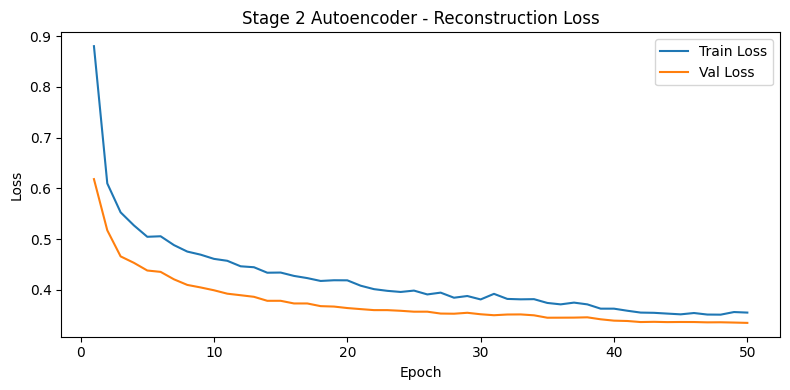

In [12]:

epochs_ae = range(1, len(history_stage2_ae["train_loss"]) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs_ae, history_stage2_ae["train_loss"], label="Train Loss")
plt.plot(epochs_ae, history_stage2_ae["val_loss"], label="Val Loss")
plt.title("Stage 2 Autoencoder - Reconstruction Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "stage2_autoencoder_reconstruction_loss.png", dpi=300, bbox_inches="tight")
plt.show()


### Bước 13. Mã hóa dữ liệu Stage 2 sang latent space

In [13]:

X_train_stage2_latent = encode_dataset(stage2_autoencoder, X_train_stage2_fs, DEVICE)
X_val_stage2_latent = encode_dataset(stage2_autoencoder, X_val_stage2_fs, DEVICE)
X_test_stage2_latent = encode_dataset(stage2_autoencoder, X_test_stage2_fs, DEVICE)

print("Stage 2 latent shapes:")
print("Train:", X_train_stage2_latent.shape)
print("Val  :", X_val_stage2_latent.shape)
print("Test :", X_test_stage2_latent.shape)

pd.DataFrame(X_train_stage2_latent[:20]).to_csv(METRIC_DIR / "stage2_latent_preview.csv", index=False)


Stage 2 latent shapes:
Train: (862, 96)
Val  : (185, 96)
Test : (186, 96)


### Bước 14. Tạo DataLoader và class weights cho classifier Stage 2

In [14]:

train_ds_stage2 = GeneDataset(X_train_stage2_latent, y_train_stage2)
val_ds_stage2 = GeneDataset(X_val_stage2_latent, y_val_stage2)
test_ds_stage2 = GeneDataset(X_test_stage2_latent, y_test_stage2)

stage2_counts = np.bincount(y_train_stage2, minlength=len(class_names_stage2))
stage2_weights = 1.0 / np.sqrt(stage2_counts)
stage2_weights = stage2_weights / stage2_weights.mean()

for i, cls in enumerate(class_names_stage2):
    stage2_weights[i] *= STAGE2_CLASS_BOOST.get(cls, 1.0)

loss_weights_stage2 = torch.tensor(stage2_weights, dtype=torch.float32).to(DEVICE)
sample_weights_stage2 = torch.tensor(stage2_weights[y_train_stage2], dtype=torch.double)
sampler_stage2 = WeightedRandomSampler(sample_weights_stage2, num_samples=len(sample_weights_stage2), replacement=True)

train_loader_stage2 = DataLoader(train_ds_stage2, batch_size=STAGE2_BATCH_SIZE, sampler=sampler_stage2)
val_loader_stage2 = DataLoader(val_ds_stage2, batch_size=STAGE2_BATCH_SIZE, shuffle=False)
test_loader_stage2 = DataLoader(test_ds_stage2, batch_size=STAGE2_BATCH_SIZE, shuffle=False)


### Bước 15. Huấn luyện classifier Stage 2 trên latent space

In [15]:

stage2_classifier = ResidualMLPClassifier(
    input_dim=LATENT_DIM_STAGE2,
    hidden_dims=STAGE2_HIDDEN_DIMS,
    num_classes=len(class_names_stage2),
    dropout=STAGE2_DROPOUT
).to(DEVICE)

criterion_stage2 = FocalLoss(alpha=loss_weights_stage2, gamma=2.0)
optimizer_stage2 = torch.optim.AdamW(stage2_classifier.parameters(), lr=STAGE2_LR, weight_decay=STAGE2_WEIGHT_DECAY)
scheduler_stage2 = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_stage2, mode="max", factor=0.5, patience=2)

history_stage2_cls = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": [],
    "train_macro_f1": [], "val_macro_f1": []
}

best_val_f1_stage2 = -1
best_state_stage2 = None
patience_counter_stage2 = 0

for epoch in range(1, STAGE2_EPOCHS + 1):
    train_loss, train_acc, train_f1 = run_cls_epoch(stage2_classifier, train_loader_stage2, criterion_stage2, DEVICE, optimizer=optimizer_stage2)
    val_loss, val_acc, val_f1 = run_cls_epoch(stage2_classifier, val_loader_stage2, criterion_stage2, DEVICE, optimizer=None)

    scheduler_stage2.step(val_f1)

    history_stage2_cls["train_loss"].append(train_loss)
    history_stage2_cls["val_loss"].append(val_loss)
    history_stage2_cls["train_acc"].append(train_acc)
    history_stage2_cls["val_acc"].append(val_acc)
    history_stage2_cls["train_macro_f1"].append(train_f1)
    history_stage2_cls["val_macro_f1"].append(val_f1)

    print(f"[Stage 2 CLS] Epoch {epoch:02d}/{STAGE2_EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Train F1: {train_f1:.4f} | Val F1: {val_f1:.4f}")

    if val_f1 > best_val_f1_stage2:
        best_val_f1_stage2 = val_f1
        best_state_stage2 = {k: v.cpu().clone() for k, v in stage2_classifier.state_dict().items()}
        patience_counter_stage2 = 0
    else:
        patience_counter_stage2 += 1

    if patience_counter_stage2 >= STAGE2_PATIENCE:
        print(f"[Stage 2 CLS] Early stopping tại epoch {epoch}.")
        break

stage2_classifier.load_state_dict(best_state_stage2)
torch.save(stage2_classifier.state_dict(), MODEL_DIR / "best_stage2_classifier.pt")
pd.DataFrame(history_stage2_cls).to_csv(METRIC_DIR / "stage2_classifier_training_history.csv", index=False)

print("Best validation macro F1 Stage 2 classifier:", best_val_f1_stage2)


[Stage 2 CLS] Epoch 01/50 | Train Loss: 0.5417 | Val Loss: 0.4170 | Train F1: 0.3604 | Val F1: 0.4114
[Stage 2 CLS] Epoch 02/50 | Train Loss: 0.4418 | Val Loss: 0.3324 | Train F1: 0.5020 | Val F1: 0.6164
[Stage 2 CLS] Epoch 03/50 | Train Loss: 0.3611 | Val Loss: 0.2898 | Train F1: 0.6168 | Val F1: 0.6837
[Stage 2 CLS] Epoch 04/50 | Train Loss: 0.3286 | Val Loss: 0.2531 | Train F1: 0.6923 | Val F1: 0.6847
[Stage 2 CLS] Epoch 05/50 | Train Loss: 0.3007 | Val Loss: 0.2222 | Train F1: 0.7405 | Val F1: 0.7028
[Stage 2 CLS] Epoch 06/50 | Train Loss: 0.2810 | Val Loss: 0.2139 | Train F1: 0.7232 | Val F1: 0.7099
[Stage 2 CLS] Epoch 07/50 | Train Loss: 0.2281 | Val Loss: 0.2129 | Train F1: 0.7852 | Val F1: 0.7263
[Stage 2 CLS] Epoch 08/50 | Train Loss: 0.2509 | Val Loss: 0.1996 | Train F1: 0.7742 | Val F1: 0.7195
[Stage 2 CLS] Epoch 09/50 | Train Loss: 0.2321 | Val Loss: 0.1899 | Train F1: 0.7748 | Val F1: 0.7167
[Stage 2 CLS] Epoch 10/50 | Train Loss: 0.2108 | Val Loss: 0.1865 | Train F1: 0.78

### Bước 16. Vẽ learning curves cho Stage 1 và Stage 2 classifier

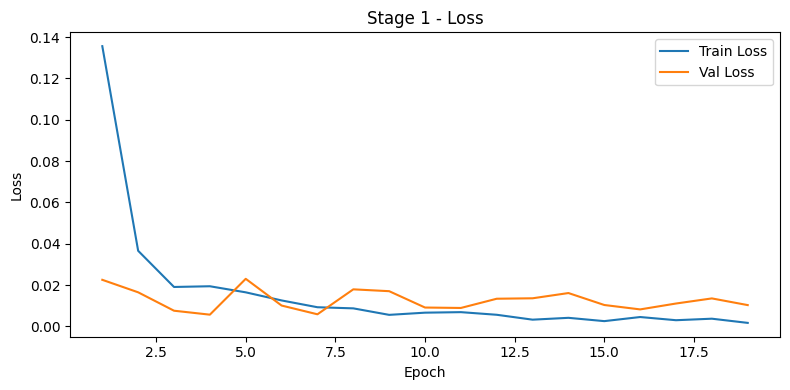

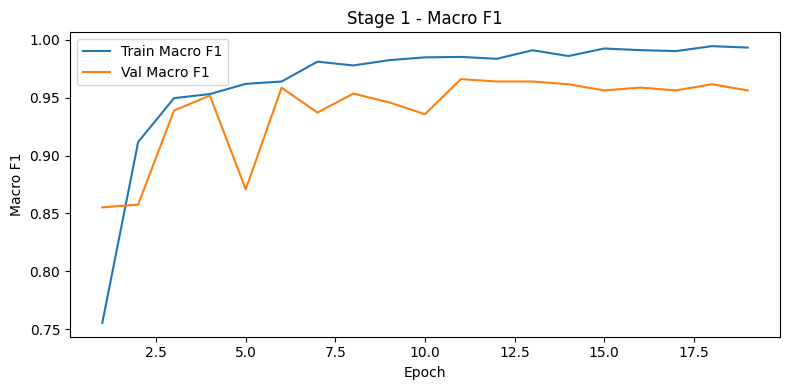

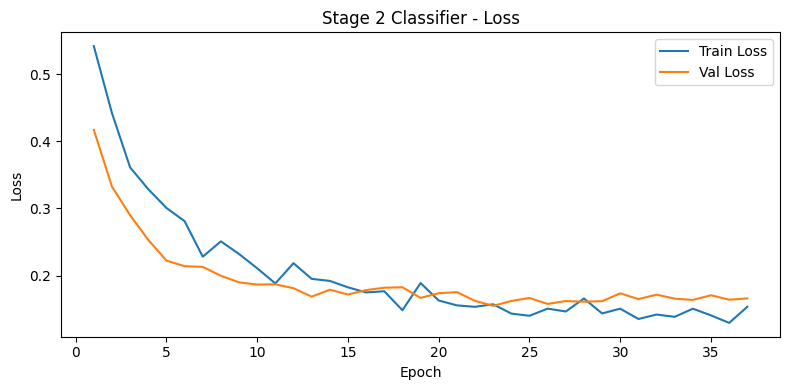

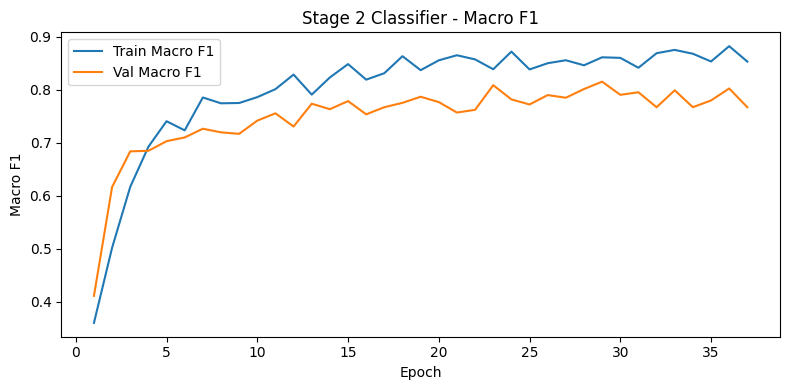

In [16]:

# Stage 1
epochs1 = range(1, len(history_stage1["train_loss"]) + 1)
plt.figure(figsize=(8, 4))
plt.plot(epochs1, history_stage1["train_loss"], label="Train Loss")
plt.plot(epochs1, history_stage1["val_loss"], label="Val Loss")
plt.title("Stage 1 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "stage1_loss.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epochs1, history_stage1["train_macro_f1"], label="Train Macro F1")
plt.plot(epochs1, history_stage1["val_macro_f1"], label="Val Macro F1")
plt.title("Stage 1 - Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "stage1_macro_f1.png", dpi=300, bbox_inches="tight")
plt.show()

# Stage 2 classifier
epochs2 = range(1, len(history_stage2_cls["train_loss"]) + 1)
plt.figure(figsize=(8, 4))
plt.plot(epochs2, history_stage2_cls["train_loss"], label="Train Loss")
plt.plot(epochs2, history_stage2_cls["val_loss"], label="Val Loss")
plt.title("Stage 2 Classifier - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "stage2_classifier_loss.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epochs2, history_stage2_cls["train_macro_f1"], label="Train Macro F1")
plt.plot(epochs2, history_stage2_cls["val_macro_f1"], label="Val Macro F1")
plt.title("Stage 2 Classifier - Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "stage2_classifier_macro_f1.png", dpi=300, bbox_inches="tight")
plt.show()


### Bước 17. Suy luận phân cấp 2-stage và xây dựng xác suất cuối cùng 6 lớp

In [17]:

# Stage 1 on all val/test
_, val_pred_stage1, val_prob_stage1 = predict_proba(stage1_model, val_loader_stage1, DEVICE)
_, test_pred_stage1, test_prob_stage1 = predict_proba(stage1_model, test_loader_stage1, DEVICE)

stage1_pred_labels_val = label_encoder_stage1.inverse_transform(val_pred_stage1)
stage1_pred_labels_test = label_encoder_stage1.inverse_transform(test_pred_stage1)

# Stage 2 latent on all val/test
X_val_all_stage2_scaled = scaler_stage2.transform(X_val)
X_val_all_stage2_fs = selector_stage2.transform(X_val_all_stage2_scaled)
X_test_all_stage2_scaled = scaler_stage2.transform(X_test)
X_test_all_stage2_fs = selector_stage2.transform(X_test_all_stage2_scaled)

X_val_all_stage2_latent = encode_dataset(stage2_autoencoder, X_val_all_stage2_fs, DEVICE)
X_test_all_stage2_latent = encode_dataset(stage2_autoencoder, X_test_all_stage2_fs, DEVICE)

val_stage2_all_ds = GeneDataset(X_val_all_stage2_latent, np.zeros(len(X_val_all_stage2_latent), dtype=int))
test_stage2_all_ds = GeneDataset(X_test_all_stage2_latent, np.zeros(len(X_test_all_stage2_latent), dtype=int))

val_stage2_all_loader = DataLoader(val_stage2_all_ds, batch_size=STAGE2_BATCH_SIZE, shuffle=False)
test_stage2_all_loader = DataLoader(test_stage2_all_ds, batch_size=STAGE2_BATCH_SIZE, shuffle=False)

_, val_pred_stage2_all, val_prob_stage2_all = predict_proba(stage2_classifier, val_stage2_all_loader, DEVICE)
_, test_pred_stage2_all, test_prob_stage2_all = predict_proba(stage2_classifier, test_stage2_all_loader, DEVICE)

stage2_pred_labels_val_all = label_encoder_stage2.inverse_transform(val_pred_stage2_all)
stage2_pred_labels_test_all = label_encoder_stage2.inverse_transform(test_pred_stage2_all)

# Hard predictions
final_val_pred_labels = stage1_pred_labels_val.copy()
final_test_pred_labels = stage1_pred_labels_test.copy()

val_pred_myeloid_idx = np.where(stage1_pred_labels_val == "Myeloid")[0]
test_pred_myeloid_idx = np.where(stage1_pred_labels_test == "Myeloid")[0]

final_val_pred_labels[val_pred_myeloid_idx] = stage2_pred_labels_val_all[val_pred_myeloid_idx]
final_test_pred_labels[test_pred_myeloid_idx] = stage2_pred_labels_test_all[test_pred_myeloid_idx]

final_val_pred = label_encoder_6class.transform(final_val_pred_labels)
final_test_pred = label_encoder_6class.transform(final_test_pred_labels)

# Final probabilities
stage1_idx = {name: i for i, name in enumerate(class_names_stage1)}
stage2_idx = {name: i for i, name in enumerate(class_names_stage2)}
final_idx = {name: i for i, name in enumerate(class_names_6class)}

final_val_prob = np.zeros((len(X_val), len(class_names_6class)))
final_test_prob = np.zeros((len(X_test), len(class_names_6class)))

final_val_prob[:, final_idx["ALL"]] = val_prob_stage1[:, stage1_idx["ALL"]]
final_val_prob[:, final_idx["CLL"]] = val_prob_stage1[:, stage1_idx["CLL"]]
final_val_prob[:, final_idx["Healthy"]] = val_prob_stage1[:, stage1_idx["Healthy"]]
final_val_prob[:, final_idx["AML"]] = val_prob_stage1[:, stage1_idx["Myeloid"]] * val_prob_stage2_all[:, stage2_idx["AML"]]
final_val_prob[:, final_idx["CML"]] = val_prob_stage1[:, stage1_idx["Myeloid"]] * val_prob_stage2_all[:, stage2_idx["CML"]]
final_val_prob[:, final_idx["MDS"]] = val_prob_stage1[:, stage1_idx["Myeloid"]] * val_prob_stage2_all[:, stage2_idx["MDS"]]

final_test_prob[:, final_idx["ALL"]] = test_prob_stage1[:, stage1_idx["ALL"]]
final_test_prob[:, final_idx["CLL"]] = test_prob_stage1[:, stage1_idx["CLL"]]
final_test_prob[:, final_idx["Healthy"]] = test_prob_stage1[:, stage1_idx["Healthy"]]
final_test_prob[:, final_idx["AML"]] = test_prob_stage1[:, stage1_idx["Myeloid"]] * test_prob_stage2_all[:, stage2_idx["AML"]]
final_test_prob[:, final_idx["CML"]] = test_prob_stage1[:, stage1_idx["Myeloid"]] * test_prob_stage2_all[:, stage2_idx["CML"]]
final_test_prob[:, final_idx["MDS"]] = test_prob_stage1[:, stage1_idx["Myeloid"]] * test_prob_stage2_all[:, stage2_idx["MDS"]]

print("Đã suy luận xong pipeline 2-stage.")
print("Validation predicted as Myeloid:", len(val_pred_myeloid_idx))
print("Test predicted as Myeloid:", len(test_pred_myeloid_idx))


Đã suy luận xong pipeline 2-stage.
Validation predicted as Myeloid: 181
Test predicted as Myeloid: 180


### Bước 18. Đánh giá cuối cùng trên bài toán 6 lớp

In [18]:

def evaluate_final_predictions(y_true, y_pred, y_prob, class_names, split_name):
    acc = accuracy_score(y_true, y_pred)
    macro_precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
    macro_recall = recall_score(y_true, y_pred, average="macro", zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    y_bin = label_binarize(y_true, classes=np.arange(len(class_names)))
    auc_macro_ovr = roc_auc_score(y_bin, y_prob, average="macro", multi_class="ovr")

    summary = pd.DataFrame([{
        "split": split_name,
        "accuracy": acc,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "auc_macro_ovr": auc_macro_ovr
    }])

    report_df = pd.DataFrame(
        classification_report(
            y_true, y_pred,
            target_names=class_names,
            output_dict=True,
            zero_division=0
        )
    ).transpose()

    return summary, report_df

val_summary, val_report = evaluate_final_predictions(
    y_val_6class, final_val_pred, final_val_prob, class_names_6class, "validation"
)
test_summary, test_report = evaluate_final_predictions(
    y_test_6class, final_test_pred, final_test_prob, class_names_6class, "test"
)

summary_df = pd.concat([val_summary, test_summary], ignore_index=True)
display(summary_df)

summary_df.to_csv(METRIC_DIR / "summary_metrics.csv", index=False)
val_report.to_csv(METRIC_DIR / "classification_report_validation.csv")
test_report.to_csv(METRIC_DIR / "classification_report_test.csv")


,split,accuracy,macro_precision,macro_recall,macro_f1,auc_macro_ovr
0,validation,0.920635,0.867168,0.916049,0.879304,0.991089
1,test,0.915567,0.857912,0.905901,0.875532,0.990164


### Bước 19. Vẽ confusion matrix cuối cùng trên tập test

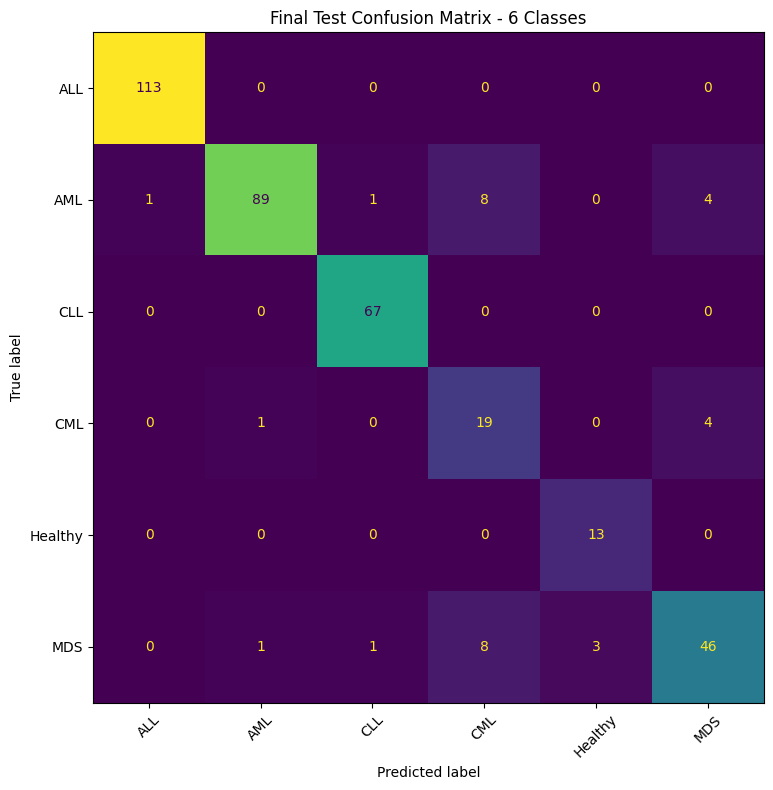

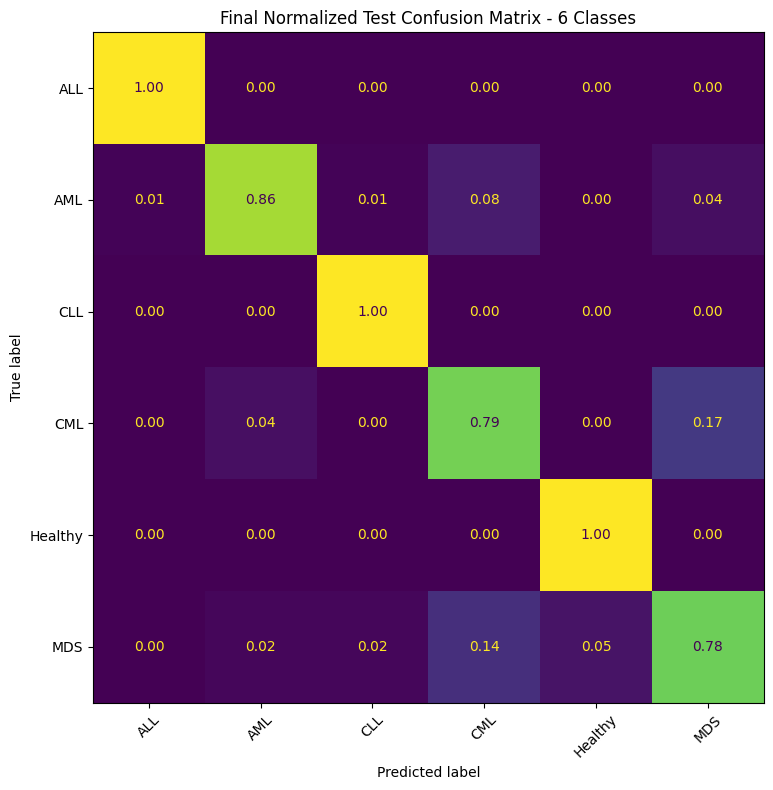

In [19]:

cm = confusion_matrix(y_test_6class, final_test_pred)
pd.DataFrame(cm, index=class_names_6class, columns=class_names_6class).to_csv(
    METRIC_DIR / "final_test_confusion_matrix.csv"
)

fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names_6class)
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Final Test Confusion Matrix - 6 Classes")
plt.tight_layout()
plt.savefig(FIG_DIR / "final_test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

cm_norm = confusion_matrix(y_test_6class, final_test_pred, normalize="true")
fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=class_names_6class)
disp.plot(ax=ax, xticks_rotation=45, colorbar=False, values_format=".2f")
plt.title("Final Normalized Test Confusion Matrix - 6 Classes")
plt.tight_layout()
plt.savefig(FIG_DIR / "final_normalized_test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


### Bước 20. Lưu object cần thiết và nhận xét sơ bộ

In [20]:

joblib.dump(label_encoder_6class, MODEL_DIR / "label_encoder_6class.pkl")

joblib.dump(label_encoder_stage1, MODEL_DIR / "label_encoder_stage1.pkl")
joblib.dump(scaler_stage1, MODEL_DIR / "scaler_stage1.pkl")
joblib.dump(selector_stage1, MODEL_DIR / "selector_stage1.pkl")

joblib.dump(label_encoder_stage2, MODEL_DIR / "label_encoder_stage2.pkl")
joblib.dump(scaler_stage2, MODEL_DIR / "scaler_stage2.pkl")
joblib.dump(selector_stage2, MODEL_DIR / "selector_stage2.pkl")

test_row = summary_df[summary_df["split"] == "test"].iloc[0]

print("=" * 78)
print("NHẬN XÉT SƠ BỘ - HIERARCHICAL TWO-STAGE AUTOENCODER-MLP")
print("=" * 78)
print(f"Accuracy test: {float(test_row['accuracy']):.4f}")
print(f"Macro Precision test: {float(test_row['macro_precision']):.4f}")
print(f"Macro Recall test: {float(test_row['macro_recall']):.4f}")
print(f"Macro F1 test: {float(test_row['macro_f1']):.4f}")
print(f"AUC macro OVR test: {float(test_row['auc_macro_ovr']):.4f}")


NHẬN XÉT SƠ BỘ - HIERARCHICAL TWO-STAGE AUTOENCODER-MLP
Accuracy test: 0.9156
Macro Precision test: 0.8579
Macro Recall test: 0.9059
Macro F1 test: 0.8755
AUC macro OVR test: 0.9902
